## Imports y setup

In [1]:
import sys, os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%load_ext autoreload
%autoreload 2

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

from src import config
from src.data import build_metadata, get_xy
from src.splits import make_split, load_split, assign_split
from src.features.egemaps import extract_egemaps
from src.features.wav2vec import extract_wav2vec, extract_wav2vec_layers, layers_to_dataframe, extract_wav2vec_frames
from src.normalize import cmvn_by_speaker, cmvn_frames_by_speaker
from src.evaluation import grouped_cv
from src.metrics import evaluate
from src.plots import plot_confusion_matrix
from src.models.mlp import MLPClassifier
from src.models.crnn import CRNNClassifier
import joblib
from src.features.augment import extract_augmented
from src.evaluation import grouped_cv_proba
from sklearn.model_selection import GroupKFold
from src.models.finetune import FineTuneClassifier
from src.predict import EmotionPredictor
from src.domain_shift import build_emodb_metadata, SHARED_EMOTIONS


sns.set_theme(style="whitegrid", context="notebook")
REPORTS_DIR = Path("reports"); REPORTS_DIR.mkdir(exist_ok=True)
META_COLS = config.META_COLS
EMOTION_ORDER = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

## Datos y split

In [2]:
metadata = build_metadata()

split = load_split() if config.SPLIT_PATH.exists() else make_split(metadata)
metadata = assign_split(metadata, split)

print(metadata.shape, "| val_actors:", split["val_actors"])
metadata.head()

(2452, 10) | val_actors: [2, 9, 11, 20]


,path,modality,vocal_channel,emotion,intensity,statement,repetition,actor,gender,split
0,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,kids,1,1,male,train
1,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,kids,2,1,male,train
2,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,dogs,1,1,male,train
3,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,dogs,2,1,male,train
4,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,calm,normal,kids,1,1,male,train


## eGeMAPS

88 features

In [3]:
egemaps_path = config.PROCESSED_DIR / "egemaps.parquet"
if egemaps_path.exists():
    egemaps = pd.read_parquet(egemaps_path)
else:
    egemaps = extract_egemaps(metadata)
    config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    egemaps.to_parquet(egemaps_path)

dataset = metadata.merge(egemaps, left_on="path", right_index=True, how="left")
dataset.to_parquet(config.PROCESSED_DIR / "dataset.parquet")
print("eGeMAPS:", egemaps.shape, "| dataset:", dataset.shape)

eGeMAPS: (2452, 88) | dataset: (2452, 98)


## wav2vec

Embeddings SSL (`wav2vec2-base`, 768-dim, mean-pooled)

In [4]:
w2v_path = config.PROCESSED_DIR / "wav2vec.parquet"
if w2v_path.exists():
    wav2vec = pd.read_parquet(w2v_path)
else:
    wav2vec = extract_wav2vec(metadata)
    config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    wav2vec.to_parquet(w2v_path)

dataset_w2v = metadata.merge(wav2vec, left_on="path", right_index=True, how="left")
dataset_w2v.to_parquet(config.PROCESSED_DIR / "dataset_wav2vec.parquet")
print("wav2vec:", wav2vec.shape, "| dataset_wav2vec:", dataset_w2v.shape)

wav2vec: (2452, 768) | dataset_wav2vec: (2452, 778)


# EDA

In [5]:
speech = dataset[dataset["vocal_channel"] == "speech"].copy()
FEAT_COLS = [c for c in dataset.columns if c not in META_COLS]

## Balance de clases

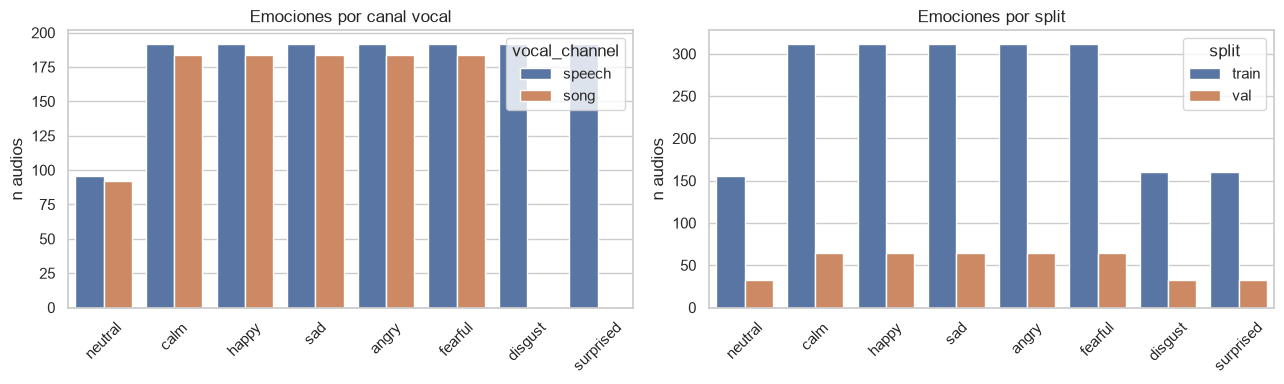

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=dataset, x="emotion", hue="vocal_channel", order=EMOTION_ORDER, ax=axes[0])
axes[0].set_title("Emociones por canal vocal"); axes[0].set_xlabel(""); axes[0].set_ylabel("n audios"); axes[0].tick_params(axis="x", rotation=45)
sns.countplot(data=dataset, x="emotion", hue="split", order=EMOTION_ORDER, ax=axes[1])
axes[1].set_title("Emociones por split"); axes[1].set_xlabel(""); axes[1].set_ylabel("n audios"); axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_class_balance.png", dpi=110, bbox_inches="tight"); plt.show()

## Distribuciones por emoción

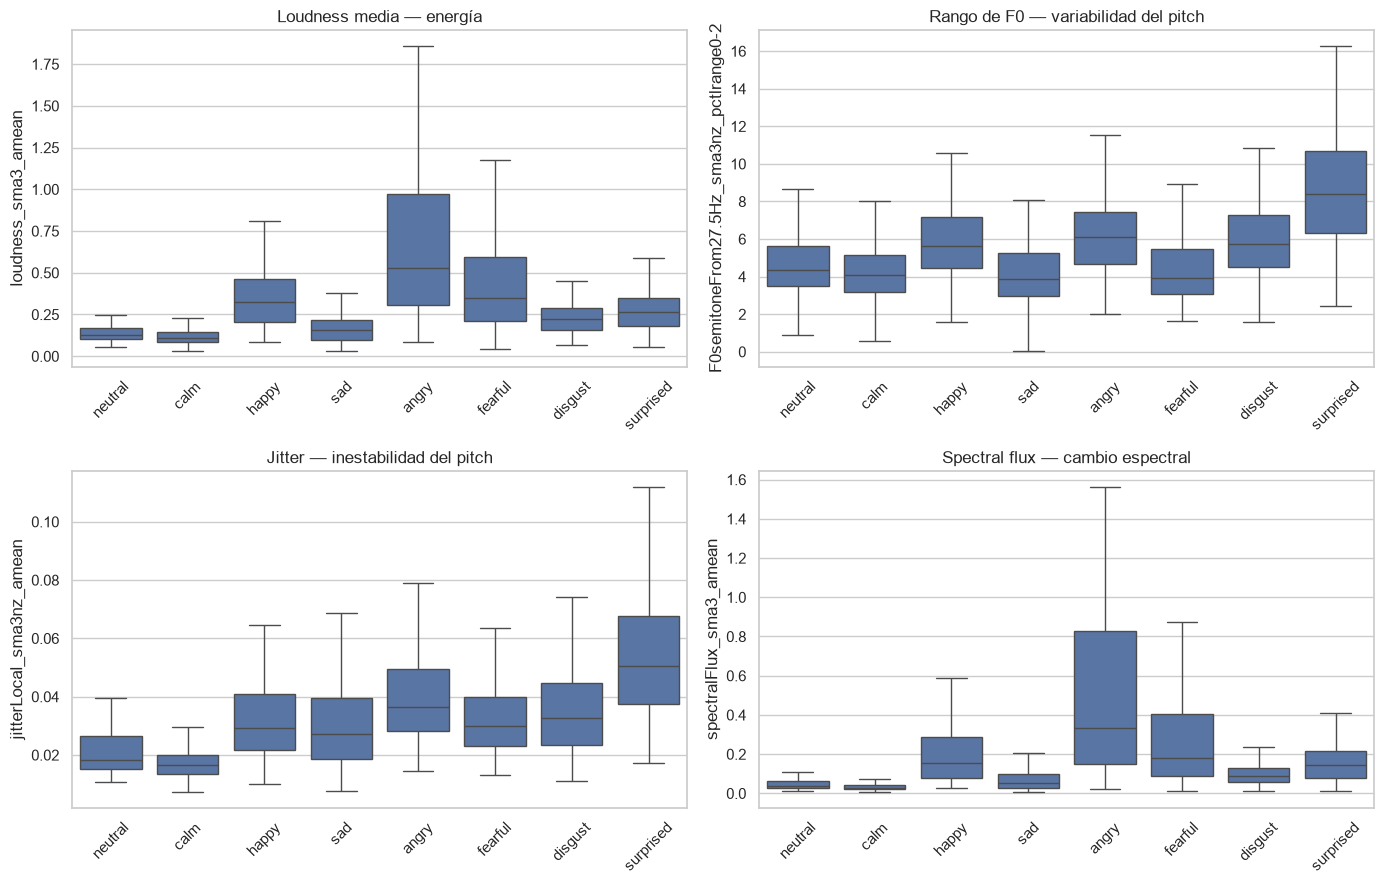

In [7]:
top_feats = [
    ("loudness_sma3_amean", "Loudness media — energía"),
    ("F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2", "Rango de F0 — variabilidad del pitch"),
    ("jitterLocal_sma3nz_amean", "Jitter — inestabilidad del pitch"),
    ("spectralFlux_sma3_amean", "Spectral flux — cambio espectral"),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (feat, title) in zip(axes.ravel(), top_feats):
    sns.boxplot(data=speech, x="emotion", y=feat, order=EMOTION_ORDER, ax=ax, showfliers=False)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_feature_dists.png", dpi=110, bbox_inches="tight"); plt.show()

## PCA 2D por emoción

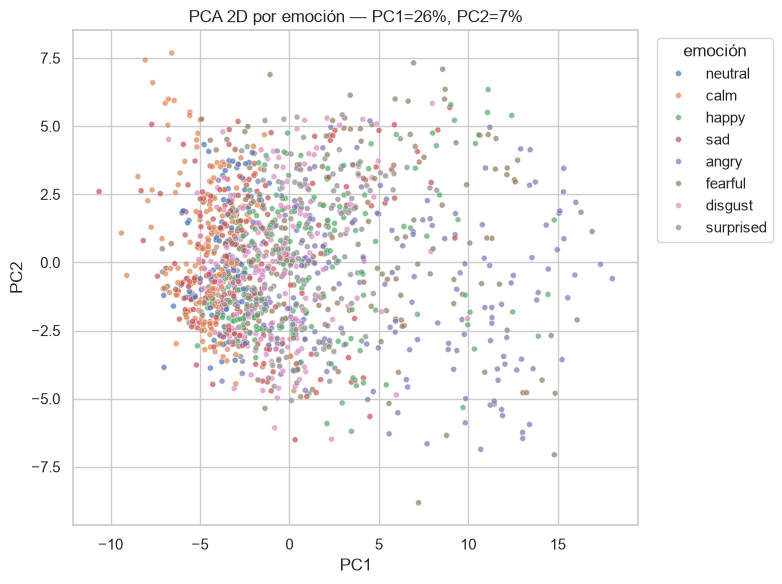

In [8]:
X_pca = np.clip(RobustScaler().fit_transform(speech[FEAT_COLS]), -5, 5)
pca = PCA(n_components=2, random_state=config.RANDOM_SEED).fit(X_pca)
pcs = pca.transform(X_pca)
speech["PC1"], speech["PC2"] = pcs[:, 0], pcs[:, 1]
var = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=speech, x="PC1", y="PC2", hue="emotion", hue_order=EMOTION_ORDER, s=18, alpha=0.7, ax=ax)
ax.set_title(f"PCA 2D por emoción — PC1={var[0]:.0f}%, PC2={var[1]:.0f}%")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="emoción")
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_pca_emotion.png", dpi=110, bbox_inches="tight"); plt.show()

## Confound: género

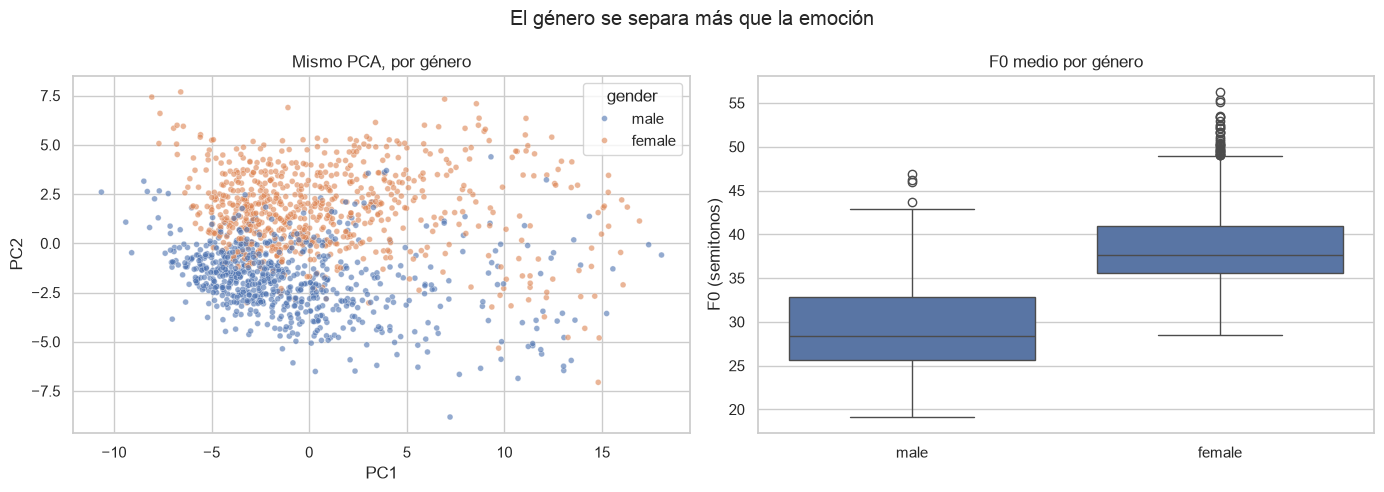

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=speech, x="PC1", y="PC2", hue="gender", s=18, alpha=0.6, ax=axes[0])
axes[0].set_title("Mismo PCA, por género")
sns.boxplot(data=speech, x="gender", y="F0semitoneFrom27.5Hz_sma3nz_amean", ax=axes[1])
axes[1].set_title("F0 medio por género"); axes[1].set_xlabel(""); axes[1].set_ylabel("F0 (semitonos)")
fig.suptitle("El género se separa más que la emoción")
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_confound_gender.png", dpi=110, bbox_inches="tight"); plt.show()

# Modelos comparación

In [10]:
Xe, y, groups = get_xy(dataset, vocal_channel="speech")
Xw, _, _      = get_xy(dataset_w2v, vocal_channel="speech")
Xc = pd.concat([Xe.reset_index(drop=True), Xw.reset_index(drop=True)], axis=1)
reps = {"eGeMAPS (88)": Xe, "wav2vec-c8 (768)": Xw, "combinado (856)": Xc}

def scaled(m):
    return make_pipeline(StandardScaler(), m)

models = {
    "RandomForest": RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=config.RANDOM_SEED, n_jobs=-1),
    "LogReg":       scaled(LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced")),
}

comp_path = config.PROCESSED_DIR / "model_comparison.parquet"
if comp_path.exists():
    comp = pd.read_parquet(comp_path)
else:
    rows = []
    for mn, model in models.items():
        for rn, X in reps.items():
            oof, _ = grouped_cv(model, X, y, groups, n_splits=5)
            m = evaluate(y, oof, labels=EMOTION_ORDER)
            rows.append({"model": mn, "rep": rn, "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]})
    comp = pd.DataFrame(rows).round(3)
    comp.to_parquet(comp_path)

acc_table = comp.pivot(index="model", columns="rep", values="accuracy").reindex(index=list(models), columns=list(reps))
f1_table  = comp.pivot(index="model", columns="rep", values="macro_f1").reindex(index=list(models), columns=list(reps))
print("Accuracy (principal):"); display(acc_table)
print("macro-F1 (secundaria):"); f1_table

Accuracy (principal):


rep,eGeMAPS (88),wav2vec-c8 (768),combinado (856)
model,,,
RandomForest,0.465,0.588,0.597
LogReg,0.518,0.721,0.727


macro-F1 (secundaria):


rep,eGeMAPS (88),wav2vec-c8 (768),combinado (856)
model,,,
RandomForest,0.449,0.576,0.582
LogReg,0.511,0.715,0.721


## Matriz de confusión del mejor modelo

Mejor (accuracy): LogReg / combinado (856) -> acc 0.727 | macro-F1 0.721


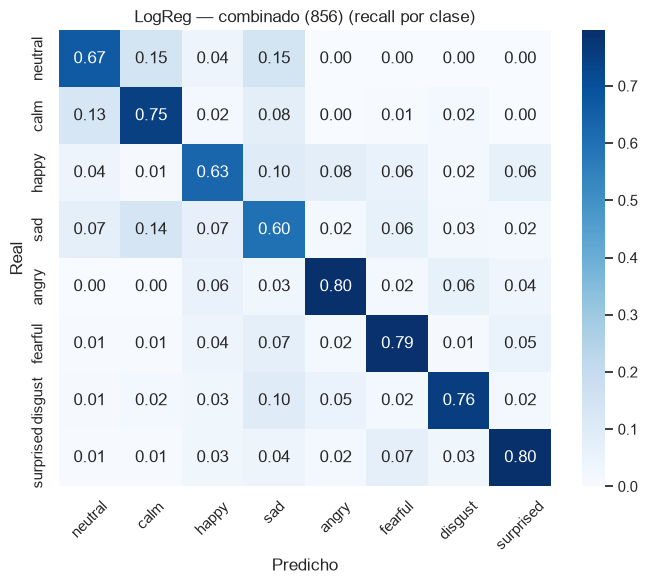

In [11]:
bm, br = acc_table.stack().idxmax()
print(f"Mejor (accuracy): {bm} / {br} -> acc {acc_table.loc[bm, br]:.3f} | macro-F1 {f1_table.loc[bm, br]:.3f}")
oof_best, _ = grouped_cv(models[bm], reps[br], y, groups, n_splits=5)
fig, ax = plot_confusion_matrix(y, oof_best, labels=EMOTION_ORDER, normalize="true",
                                title=f"{bm} — {br} (recall por clase)")
ax.tick_params(axis="x", rotation=45); fig.tight_layout()
fig.savefig(REPORTS_DIR / "best_model_confusion.png", dpi=110, bbox_inches="tight"); plt.show()

# Investigación capas de wav2vec

Qué capa rinde mejor para emoción.

In [12]:
layers_path = config.PROCESSED_DIR / "wav2vec_layers.npz"
if layers_path.exists():
    _npz = np.load(layers_path, allow_pickle=True)
    layer_emb, layer_paths = _npz["emb"], [str(p) for p in _npz["paths"]]
else:
    layer_emb, layer_paths = extract_wav2vec_layers(metadata)
    config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    np.savez(layers_path, emb=layer_emb, paths=np.array(layer_paths, dtype=object))
assert layer_paths == metadata["path"].tolist()

sweep_path = config.PROCESSED_DIR / "wav2vec_layer_sweep.parquet"
if sweep_path.exists():
    sweep = pd.read_parquet(sweep_path)
else:
    mask = (metadata["vocal_channel"] == "speech").to_numpy()
    ys, gs = metadata.loc[mask, "emotion"], metadata.loc[mask, "actor"]
    rows = []
    for l in range(layer_emb.shape[1]):
        rf_l = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=config.RANDOM_SEED, n_jobs=-1)
        oof_l, _ = grouped_cv(rf_l, layer_emb[mask, l, :], ys, gs, n_splits=5)
        m = evaluate(ys, oof_l, labels=EMOTION_ORDER)
        rows.append({"layer": l, "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]})
    sweep = pd.DataFrame(rows)
    sweep.to_parquet(sweep_path)
sweep

,layer,accuracy,macro_f1
0,0,0.472222,0.461267
1,1,0.497222,0.480091
2,2,0.529861,0.513858
3,3,0.538889,0.522706
4,4,0.555556,0.538875
5,5,0.584722,0.570671
6,6,0.592361,0.575530
7,7,0.588194,0.574737
8,8,0.592361,0.578493
9,9,0.552083,0.536499


## Rendimiento según la capa

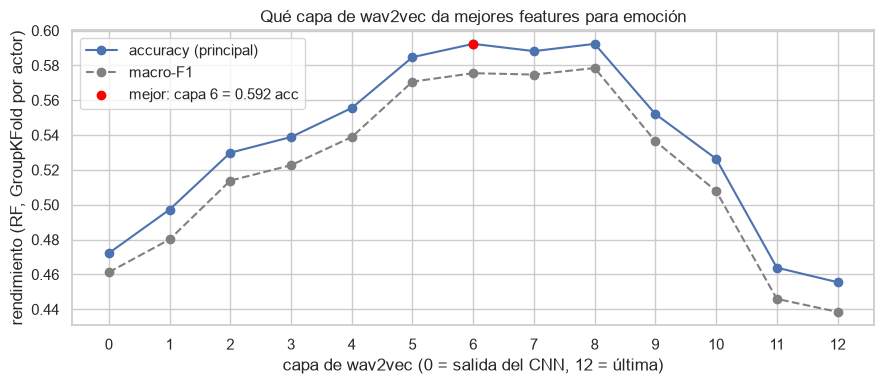

In [13]:
best = sweep.loc[sweep["accuracy"].idxmax()]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sweep["layer"], sweep["accuracy"], marker="o", label="accuracy (principal)")
ax.plot(sweep["layer"], sweep["macro_f1"], marker="o", linestyle="--", color="gray", label="macro-F1")
ax.scatter([best["layer"]], [best["accuracy"]], color="red", zorder=5,
           label=f"mejor: capa {int(best['layer'])} = {best['accuracy']:.3f} acc")
ax.set_xlabel("capa de wav2vec (0 = salida del CNN, 12 = última)")
ax.set_ylabel("rendimiento (RF, GroupKFold por actor)")
ax.set_title("Qué capa de wav2vec da mejores features para emoción")
ax.set_xticks(range(len(sweep))); ax.legend()
fig.tight_layout(); fig.savefig(REPORTS_DIR / "wav2vec_layer_sweep.png", dpi=110, bbox_inches="tight"); plt.show()

# Investigación feature engineering

## Importancia de features

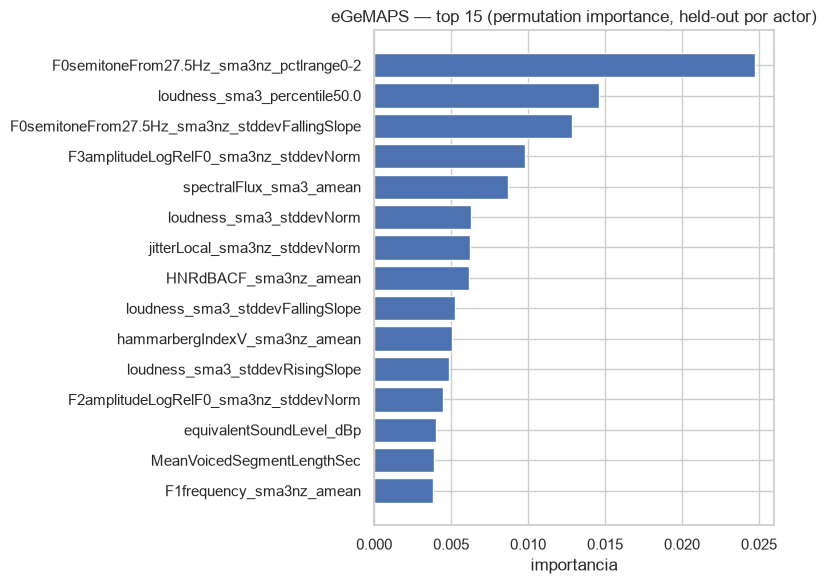

Contribución en el RF combinado -> eGeMAPS: 16.6% | wav2vec: 83.4%


In [14]:
imp = pd.read_parquet(config.PROCESSED_DIR / "egemaps_perm_importance.parquet")
contrib = json.load(open(config.PROCESSED_DIR / "contribution.json"))

fig, ax = plt.subplots(figsize=(8, 6))
top15 = imp.head(15).iloc[::-1]
ax.barh(top15["feature"], top15["importance"])
ax.set_title("eGeMAPS — top 15 (permutation importance, held-out por actor)")
ax.set_xlabel("importancia")
fig.tight_layout(); fig.savefig(REPORTS_DIR / "egemaps_importance.png", dpi=110, bbox_inches="tight"); plt.show()

print(f"Contribución en el RF combinado -> eGeMAPS: {contrib['egemaps_share']:.1%} | wav2vec: {contrib['wav2vec_share']:.1%}")

## Feature selection (top-k)

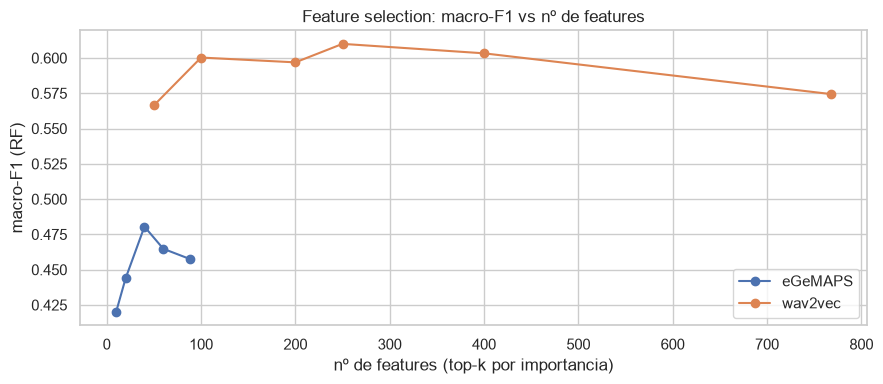

rep,eGeMAPS,wav2vec
k,,
10,0.4201,NaN
20,0.4438,NaN
40,0.4805,NaN
50,NaN,0.5664
60,0.4648,NaN
88,0.4576,NaN
100,NaN,0.6003
200,NaN,0.5969
250,NaN,0.6100


In [15]:
fs = pd.read_parquet(config.PROCESSED_DIR / "feature_selection.parquet")
fig, ax = plt.subplots(figsize=(9, 4))
for rep, g in fs.groupby("rep"):
    ax.plot(g["k"], g["macro_f1"], marker="o", label=rep)
ax.set_xlabel("nº de features (top-k por importancia)"); ax.set_ylabel("macro-F1 (RF)")
ax.set_title("Feature selection: macro-F1 vs nº de features"); ax.legend()
fig.tight_layout(); fig.savefig(REPORTS_DIR / "feature_selection.png", dpi=110, bbox_inches="tight"); plt.show()
fs.pivot(index="k", columns="rep", values="macro_f1")

## Decorrelación / PCA

In [16]:
corr_stats = json.load(open(config.PROCESSED_DIR / "decorr_corr.json"))
dec = pd.read_parquet(config.PROCESSED_DIR / "decorrelation.parquet")
print("eGeMAPS: pares |r|>0.95 =", corr_stats["egemaps_pairs_gt_0.95"],
      "| |r|>0.90 =", corr_stats["egemaps_pairs_gt_0.90"],
      "| mediana |r| =", round(corr_stats["egemaps_median_abs_r"], 3))
print("wav2vec: pares |r|>0.80 =", corr_stats["wav2vec_pairs_gt_0.80"])
dec

eGeMAPS: pares |r|>0.95 = 27 | |r|>0.90 = 45 | mediana |r| = 0.109
wav2vec: pares |r|>0.80 = 0


,variante,macro_f1
0,eGeMAPS raw (88),0.4486
1,eGeMAPS PCA-95%,0.4527
2,wav2vec raw (768),0.5756
3,wav2vec PCA-90%,0.5902


# Modelo ""final"" -> CMVN + multi-capa

Normalización por hablante y top-3 capas.

In [17]:
top3 = layers_to_dataframe(layer_emb, layer_paths, config.WAV2VEC_TOP_LAYERS)
speech_paths = dataset.loc[dataset["vocal_channel"] == "speech", "path"]
Xe_  = Xe.reset_index(drop=True)
Xw_  = Xw.reset_index(drop=True)
Xw3_ = top3.loc[speech_paths].reset_index(drop=True)
y_, g_ = y.reset_index(drop=True), groups.reset_index(drop=True)

def lr():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000, class_weight="balanced"))
def score(X):
    oof, _ = grouped_cv(lr(), X, y_, g_, n_splits=5)
    m = evaluate(y_, oof, labels=EMOTION_ORDER)
    return {"accuracy": round(m["accuracy"], 3), "macro_f1": round(m["macro_f1"], 3)}

comb = pd.concat([Xw3_, Xe_], axis=1)
reps_imp = {
    "wav2vec-c8":             Xw_,
    "wav2vec-c8 + CMVN":      cmvn_by_speaker(Xw_, g_),
    "top-3 capas":            Xw3_,
    "top-3 + CMVN":           cmvn_by_speaker(Xw3_, g_),
    "top-3 + eGeMAPS":        comb,
    "top-3 + eGeMAPS + CMVN": cmvn_by_speaker(comb, g_),
}

imp_path = config.PROCESSED_DIR / "improvements.parquet"
if imp_path.exists():
    improvements = pd.read_parquet(imp_path)
else:
    improvements = pd.DataFrame({k: score(X) for k, X in reps_imp.items()}).T[["accuracy", "macro_f1"]]
    improvements.to_parquet(imp_path)
improvements

,accuracy,macro_f1
wav2vec-c8,0.732,0.727
wav2vec-c8 + CMVN,0.803,0.797
top-3 capas,0.736,0.731
top-3 + CMVN,0.822,0.815
top-3 + eGeMAPS,0.751,0.746
top-3 + eGeMAPS + CMVN,0.827,0.821


## Matriz de confusión del modelo final

Modelo final — accuracy: 0.827 | macro-F1: 0.821


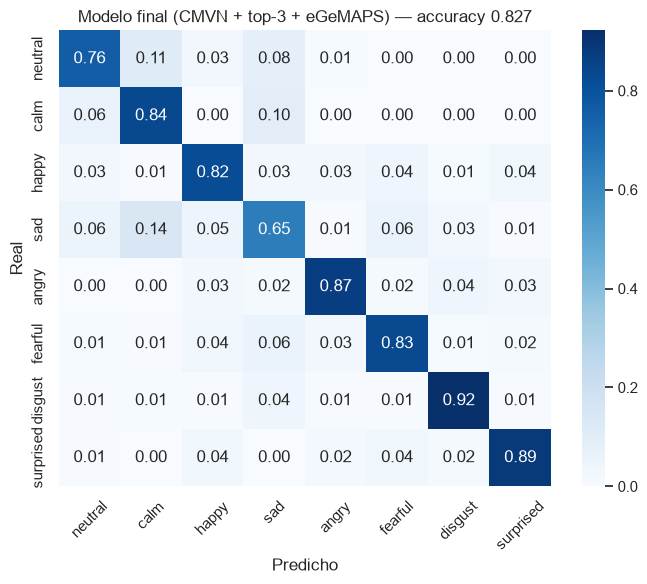

In [18]:
Xf = reps_imp["top-3 + eGeMAPS + CMVN"]
oof_f, _ = grouped_cv(lr(), Xf, y_, g_, n_splits=5)
m = evaluate(y_, oof_f, labels=EMOTION_ORDER)
print(f"Modelo final — accuracy: {m['accuracy']:.3f} | macro-F1: {m['macro_f1']:.3f}")
fig, ax = plot_confusion_matrix(y_, oof_f, labels=EMOTION_ORDER, normalize="true",
                                title=f"Modelo final (CMVN + top-3 + eGeMAPS) — accuracy {m['accuracy']:.3f}")
ax.tick_params(axis="x", rotation=45); fig.tight_layout()
fig.savefig(REPORTS_DIR / "final_model_confusion.png", dpi=110, bbox_inches="tight"); plt.show()

# Redes neuronales

## MLP sobre features pooled

In [19]:
Xcmvn = reps_imp["top-3 + eGeMAPS + CMVN"]

nn_path = config.PROCESSED_DIR / "nn_comparison.parquet"
if nn_path.exists():
    nn_table = pd.read_parquet(nn_path)
else:
    mlp = MLPClassifier(hidden=(512, 256), dropout=0.3, lr=1e-3, max_epochs=100, patience=12)
    oof_mlp, _ = grouped_cv(mlp, Xcmvn, y_, g_, n_splits=5)
    m = evaluate(y_, oof_mlp, labels=EMOTION_ORDER)
    lr_final = improvements.loc["top-3 + eGeMAPS + CMVN"]
    nn_table = pd.DataFrame([
        {"model": "LogReg", "accuracy": lr_final["accuracy"], "macro_f1": lr_final["macro_f1"]},
        {"model": "MLP",    "accuracy": round(m["accuracy"], 3), "macro_f1": round(m["macro_f1"], 3)},
    ]).set_index("model")
    nn_table.to_parquet(nn_path)
nn_table

,accuracy,macro_f1
model,,
LogReg,0.827,0.821
MLP,0.796,0.792


## Curva de entrenamiento (una corrida)

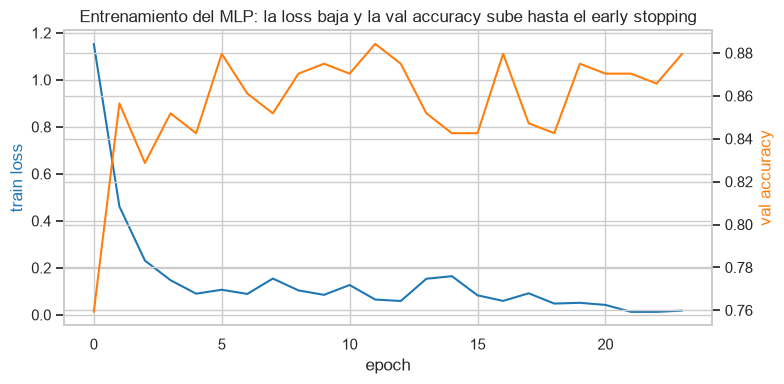

In [20]:
demo = MLPClassifier(hidden=(512, 256), dropout=0.3, max_epochs=100, patience=12).fit(Xcmvn.values, y_.values)
hist = pd.DataFrame(demo.history_)

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(hist["epoch"], hist["train_loss"], color="tab:blue")
ax1.set_xlabel("epoch"); ax1.set_ylabel("train loss", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(hist["epoch"], hist["val_acc"], color="tab:orange")
ax2.set_ylabel("val accuracy", color="tab:orange")
ax1.set_title("Entrenamiento del MLP: la loss baja y la val accuracy sube hasta el early stopping")
fig.tight_layout(); fig.savefig(REPORTS_DIR / "mlp_training.png", dpi=110, bbox_inches="tight"); plt.show()

## CRNN sobre secuencias frame-level

In [21]:
speech_meta = metadata[metadata["vocal_channel"] == "speech"].reset_index(drop=True)

frames_path = config.PROCESSED_DIR / "wav2vec_frames_top3.npz"
if not frames_path.exists():
    seqs_raw, fpaths = extract_wav2vec_frames(speech_meta, layers=config.WAV2VEC_TOP_LAYERS)
    obj = np.empty(len(seqs_raw), dtype=object)
    for i, s in enumerate(seqs_raw):
        obj[i] = s.astype("float16")
    np.savez(frames_path, emb=obj, paths=np.array(fpaths, dtype=object))

crnn_oof_path = config.PROCESSED_DIR / "crnn_top3_oof.parquet"
if crnn_oof_path.exists():
    crnn_oof = pd.read_parquet(crnn_oof_path)
else:
    _npz = np.load(frames_path, allow_pickle=True)
    seqs = cmvn_frames_by_speaker([np.asarray(s, dtype="float32") for s in _npz["emb"]], g_.to_numpy())
    oof_c, _ = grouped_cv(CRNNClassifier(max_epochs=40, patience=8), seqs, y_, g_, n_splits=5)
    crnn_oof = pd.DataFrame({"y_true": y_.to_numpy(), "y_pred": oof_c.to_numpy()})
    crnn_oof.to_parquet(crnn_oof_path)

crnn_m = evaluate(crnn_oof["y_true"], crnn_oof["y_pred"], labels=EMOTION_ORDER)
print(f"CRNN (top-3 frame) -> accuracy {crnn_m['accuracy']:.3f} | macro-F1 {crnn_m['macro_f1']:.3f}")

CRNN (top-3 frame) -> accuracy 0.751 | macro-F1 0.745


## Comparación final: lineal vs redes

In [22]:
def _m(path):
    d = pd.read_parquet(config.PROCESSED_DIR / path)
    return evaluate(d["y_true"], d["y_pred"], labels=EMOTION_ORDER)

lr_final = improvements.loc["top-3 + eGeMAPS + CMVN"]
rows = [
    {"modelo": "LogReg (lineal, pooled)", "accuracy": lr_final["accuracy"],          "macro_f1": lr_final["macro_f1"]},
    {"modelo": "MLP (pooled)",            "accuracy": nn_table.loc["MLP", "accuracy"], "macro_f1": nn_table.loc["MLP", "macro_f1"]},
]
for name, path in [("CRNN (capa 8, frame)", "crnn_oof.parquet"), ("CRNN (top-3, frame)", "crnn_top3_oof.parquet")]:
    m = _m(path)
    rows.append({"modelo": name, "accuracy": round(m["accuracy"], 3), "macro_f1": round(m["macro_f1"], 3)})
comparison = pd.DataFrame(rows).set_index("modelo")
comparison

,accuracy,macro_f1
modelo,,
"LogReg (lineal, pooled)",0.827,0.821
MLP (pooled),0.796,0.792
"CRNN (capa 8, frame)",0.763,0.757
"CRNN (top-3, frame)",0.751,0.745


## Matriz de confusión del CRNN

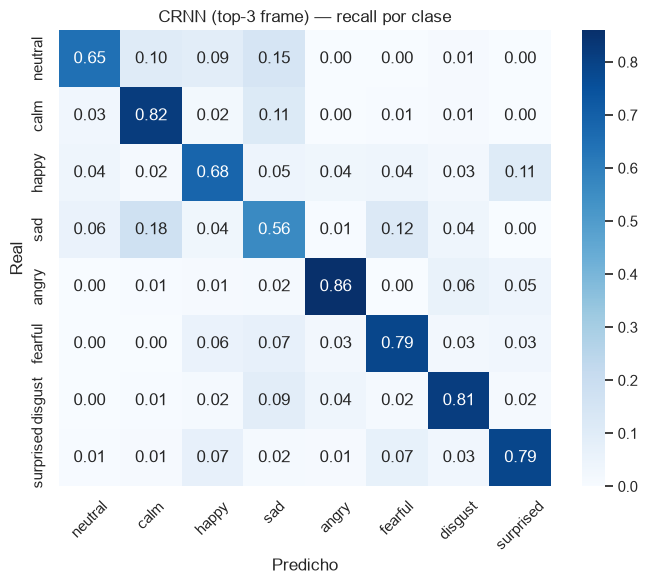

In [23]:
fig, ax = plot_confusion_matrix(crnn_oof["y_true"], crnn_oof["y_pred"], labels=EMOTION_ORDER,
                                normalize="true", title="CRNN (top-3 frame) — recall por clase")
ax.tick_params(axis="x", rotation=45); fig.tight_layout()
fig.savefig(REPORTS_DIR / "crnn_confusion.png", dpi=110, bbox_inches="tight"); plt.show()

# Optimización avanzada (audio-only)

In [24]:

adv_meta = metadata[metadata["vocal_channel"] == "speech"].reset_index(drop=True)
adv_paths = adv_meta["path"]; y_adv = adv_meta["emotion"].to_numpy(); g_adv = adv_meta["actor"].to_numpy()
WAVLM_L, HUBERT_L, BASE_L = [13, 11, 10], [13, 14, 12], config.WAV2VEC_TOP_LAYERS
EMO = EMOTION_ORDER

def ensure_layers(npz, model_name):
    """Embeddings por-capa del cache; si falta, los extrae con el modelo SSL y los guarda."""
    p = config.PROCESSED_DIR / npz
    if p.exists():
        d = np.load(p, allow_pickle=True); return d["emb"], [str(x) for x in d["paths"]]
    emb, paths = extract_wav2vec_layers(adv_meta, model_name=model_name)
    np.savez(p, emb=emb, paths=np.array(paths, dtype=object)); return emb, paths

def load_top(npz, model_name, layers):
    emb, paths = ensure_layers(npz, model_name)
    return layers_to_dataframe(emb, paths, layers).loc[adv_paths].reset_index(drop=True)

def load_aug(npz, model_name, layers):
    """Features aumentadas (limpias + 3 pseudo-hablantes); si faltan, las extrae y guarda.
    ya/ga (emoción/actor de cada aumentado) se derivan del orden: 3 augs por audio."""
    p = config.PROCESSED_DIR / npz
    ya, ga = np.repeat(y_adv, 3), np.repeat(g_adv, 3)
    if p.exists():
        d = np.load(p, allow_pickle=True); return d["Xc"], d["Xa"], ya, ga
    Xc, Xa, _, _ = extract_augmented(adv_meta, model_name=model_name, layers=layers)
    np.savez(p, Xc=Xc, Xa=Xa); return Xc, Xa, ya, ga

def adv_lr():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000, class_weight="balanced"))

## Modelo mas potente WavLM-large

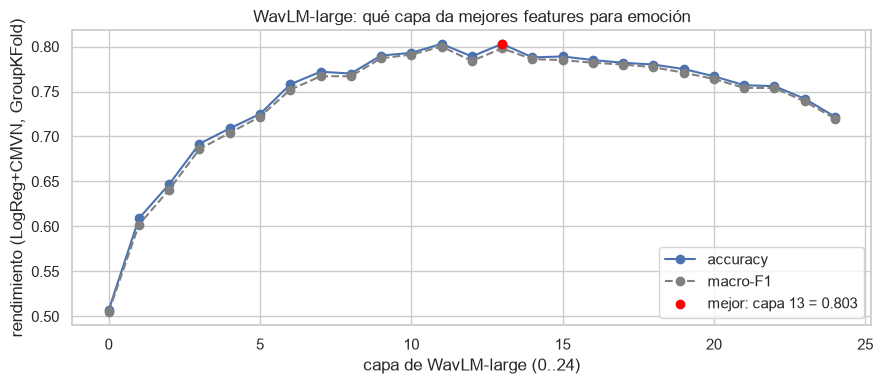

In [25]:
wsweep_path = config.PROCESSED_DIR / "wavlm_layer_sweep.parquet"
if wsweep_path.exists():
    wsweep = pd.read_parquet(wsweep_path)
else:
    emb, _ = ensure_layers("wavlm_large_layers.npz", "microsoft/wavlm-large")
    rows = []
    for l in range(emb.shape[1]):
        m = evaluate(y_adv, grouped_cv(adv_lr(), pd.DataFrame(emb[:, l, :]), y_adv, g_adv, 5)[0], labels=EMO)
        rows.append({"layer": l, "acc": round(m["accuracy"], 3), "f1": round(m["macro_f1"], 3)})
    wsweep = pd.DataFrame(rows); wsweep.to_parquet(wsweep_path)

best = wsweep.sort_values("acc", ascending=False).iloc[0]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(wsweep["layer"], wsweep["acc"], marker="o", label="accuracy")
ax.plot(wsweep["layer"], wsweep["f1"], marker="o", linestyle="--", color="gray", label="macro-F1")
ax.scatter([best["layer"]], [best["acc"]], color="red", zorder=5,
           label=f"mejor: capa {int(best['layer'])} = {best['acc']:.3f}")
ax.set_xlabel("capa de WavLM-large (0..24)"); ax.set_ylabel("rendimiento (LogReg+CMVN, GroupKFold)")
ax.set_title("WavLM-large: qué capa da mejores features para emoción"); ax.legend()
fig.tight_layout(); fig.savefig(REPORTS_DIR / "wavlm_layer_sweep.png", dpi=110, bbox_inches="tight"); plt.show()

## Combinación de representaciones

In [26]:
combos_path = config.PROCESSED_DIR / "adv_combos.parquet"
if combos_path.exists():
    adv_combos = pd.read_parquet(combos_path)
else:
    wavlm = load_top("wavlm_large_layers.npz", "microsoft/wavlm-large", WAVLM_L)
    base = load_top("wav2vec_layers.npz", "facebook/wav2vec2-base", BASE_L)
    ege = get_xy(pd.read_parquet(config.PROCESSED_DIR / "dataset.parquet"), vocal_channel="speech")[0].reset_index(drop=True)
    def sc(X):
        m = evaluate(y_adv, grouped_cv(adv_lr(), cmvn_by_speaker(X, g_adv), y_adv, g_adv, 5)[0], labels=EMO)
        return round(m["accuracy"], 3), round(m["macro_f1"], 3)
    rows = []
    for name, X in [("WavLM top-3 + CMVN", wavlm),
                    ("WavLM + eGeMAPS + CMVN", pd.concat([wavlm, ege], axis=1)),
                    ("WavLM + base + CMVN", pd.concat([wavlm, base], axis=1)),
                    ("WavLM + base + eGeMAPS + CMVN", pd.concat([wavlm, base, ege], axis=1))]:
        a, f = sc(X); rows.append({"representacion": name, "accuracy": a, "macro_f1": f})
    adv_combos = pd.DataFrame(rows); adv_combos.to_parquet(combos_path)
adv_combos

,representacion,accuracy,macro_f1
0,WavLM top-3 + CMVN,0.864,0.863
1,WavLM + eGeMAPS + CMVN,0.868,0.867
2,WavLM + base + CMVN,0.868,0.866
3,WavLM + base + eGeMAPS + CMVN,0.873,0.871


## Data augmentation pseudo-hablantes

Deformar el audio simula otros hablantes.

In [27]:
augment_path = config.PROCESSED_DIR / "adv_augment.parquet"
if augment_path.exists():
    adv_augment = pd.read_parquet(augment_path)
else:
    Xc, Xa, ya, ga = load_aug("wavlm_aug_feats.npz", "microsoft/wavlm-large", WAVLM_L)
    Xc_df, Xa_df = pd.DataFrame(Xc), pd.DataFrame(Xa)
    def cv_aug(make_clf):
        oof = np.empty(len(y_adv), object)
        for tr, te in GroupKFold(5).split(np.zeros(len(y_adv)), y_adv, g_adv):
            sel = np.isin(ga, list(set(g_adv[tr])))
            Xtr = cmvn_by_speaker(pd.concat([Xc_df.iloc[tr], Xa_df[sel]], ignore_index=True), np.concatenate([g_adv[tr], ga[sel]]))
            clf = make_clf().fit(Xtr, np.concatenate([y_adv[tr], ya[sel]]))
            oof[te] = clf.predict(cmvn_by_speaker(Xc_df.iloc[te].reset_index(drop=True), g_adv[te]))
        return round(evaluate(y_adv, oof, labels=EMO)["accuracy"], 3)
    rows = []
    for name, mk in [("LogReg", adv_lr), ("MLP", lambda: MLPClassifier(hidden=(512, 256), dropout=0.3, max_epochs=100, patience=12))]:
        no_aug = round(evaluate(y_adv, grouped_cv(mk(), cmvn_by_speaker(Xc_df, g_adv), y_adv, g_adv, 5)[0], labels=EMO)["accuracy"], 3)
        rows.append({"modelo": name, "acc_sin_aug": no_aug, "acc_con_aug": cv_aug(mk)})
    adv_augment = pd.DataFrame(rows); adv_augment.to_parquet(augment_path)
adv_augment

,modelo,acc_sin_aug,acc_con_aug
0,LogReg,0.864,0.869
1,MLP,0.847,0.876


## Multi-modelo + ensemble

Varios modelos combinados por votación.

In [28]:
ensemble_path = config.PROCESSED_DIR / "adv_ensemble.parquet"
if ensemble_path.exists():
    adv_ensemble = pd.read_parquet(ensemble_path)
else:
    wavlm = load_top("wavlm_large_layers.npz", "microsoft/wavlm-large", WAVLM_L)
    hub = load_top("hubert_large_layers.npz", "facebook/hubert-large-ll60k", HUBERT_L)
    base = load_top("wav2vec_layers.npz", "facebook/wav2vec2-base", BASE_L)
    Pw = grouped_cv_proba(adv_lr(), cmvn_by_speaker(wavlm, g_adv), y_adv, g_adv, EMO)
    Ph = grouped_cv_proba(adv_lr(), cmvn_by_speaker(hub, g_adv), y_adv, g_adv, EMO)
    Pb = grouped_cv_proba(adv_lr(), cmvn_by_speaker(base, g_adv), y_adv, g_adv, EMO)
    awl = load_aug("wavlm_aug_feats.npz", "microsoft/wavlm-large", WAVLM_L)
    ab = load_aug("base_aug_feats.npz", "facebook/wav2vec2-base", BASE_L)
    wlb_c = pd.DataFrame(np.hstack([awl[0], ab[0]])); wlb_a = pd.DataFrame(np.hstack([awl[1], ab[1]])); ya_m, ga_m = awl[2], awl[3]
    Pm = np.zeros((len(y_adv), len(EMO)))
    for tr, te in GroupKFold(5).split(np.zeros(len(y_adv)), y_adv, g_adv):
        sel = np.isin(ga_m, list(set(g_adv[tr])))
        Xtr = cmvn_by_speaker(pd.concat([wlb_c.iloc[tr], wlb_a[sel]], ignore_index=True), np.concatenate([g_adv[tr], ga_m[sel]]))
        clf = MLPClassifier(hidden=(512, 256), dropout=0.3, max_epochs=100, patience=12).fit(Xtr, np.concatenate([y_adv[tr], ya_m[sel]]))
        p = clf.predict_proba(cmvn_by_speaker(wlb_c.iloc[te].reset_index(drop=True), g_adv[te]))
        for j, c in enumerate(clf.classes_):
            Pm[te, EMO.index(c)] = p[:, j]
    def ens(P):
        m = evaluate(y_adv, np.array(EMO)[P.argmax(1)], labels=EMO); return round(m["accuracy"], 3), round(m["macro_f1"], 3)
    rows = []
    for name, P in [("3 backbones (WavLM+HuBERT+base)", Pw + Ph + Pb), ("3bb + MLP+aug", Pw + Ph + Pb + Pm),
                    ("W+H(2x) + base + MLP+aug (mejor)", 2 * Pw + 2 * Ph + Pb + Pm)]:
        a, f = ens(P); rows.append({"ensemble": name, "accuracy": a, "macro_f1": f})
    adv_ensemble = pd.DataFrame(rows); adv_ensemble.to_parquet(ensemble_path)
adv_ensemble

,ensemble,accuracy,macro_f1
0,3 backbones (WavLM+HuBERT+base),0.882,0.880
1,3bb + MLP+aug,0.888,0.886
2,W+H(2x) + base + MLP+aug (mejor),0.890,0.888


## Fine-tuning end-to-end

Entrenar el backbone completo; con pocos datos no mejora.

In [29]:
RUN_FINETUNE = False

finetune_path = config.PROCESSED_DIR / "adv_finetune.parquet"
if RUN_FINETUNE and not finetune_path.exists():
    Xp = adv_meta["path"].to_numpy(); rows = []
    for k, (tr, te) in enumerate(GroupKFold(5).split(np.zeros(len(y_adv)), y_adv, g_adv)):
        clf = FineTuneClassifier(model_name="microsoft/wavlm-large", augment=True, lr=2e-5,
                                 batch_size=8, max_epochs=60, patience=10).fit(Xp[tr], y_adv[tr])
        m = evaluate(y_adv[te], clf.predict(Xp[te]), labels=EMO)
        rows.append({"modelo": f"WavLM-large + aug (fold {k+1})", "accuracy": round(m["accuracy"], 3),
                     "macro_f1": round(m["macro_f1"], 3), "config": "lr 2e-5, batch 8"})
    pd.DataFrame(rows).to_parquet(finetune_path)
pd.read_parquet(finetune_path)

,modelo,accuracy,macro_f1,config
0,wav2vec2-base (1 fold),0.733,0.715,"lr 2e-5, freeze0"
1,WavLM-large + aug (fold 1),0.777,0.777,"lr 2e-5, batch 8"
2,WavLM-large + aug (fold 2),0.767,0.763,"lr 2e-5, batch 8"
3,WavLM-large + aug (fold 3),0.767,0.756,"lr 2e-5, batch 8"
4,WavLM-large + aug (fold 4),0.840,0.834,"lr 2e-5, batch 8"


# Modelo final

Recorrido, modelo ganador y entrenamiento final.

## Recorrido de optimización

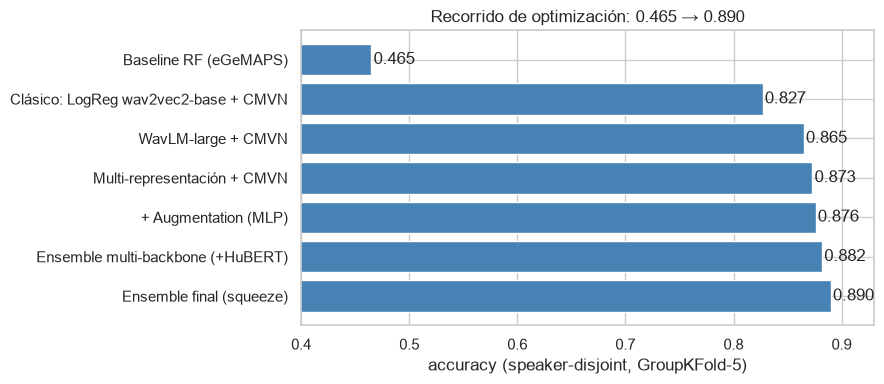

,etapa,accuracy
0,Baseline RF (eGeMAPS),0.465
1,Clásico: LogReg wav2vec2-base + CMVN,0.827
2,WavLM-large + CMVN,0.865
3,Multi-representación + CMVN,0.873
4,+ Augmentation (MLP),0.876
5,Ensemble multi-backbone (+HuBERT),0.882
6,Ensemble final (squeeze),0.890


In [30]:
journey = pd.DataFrame([
    ("Baseline RF (eGeMAPS)",                 0.465),
    ("Clásico: LogReg wav2vec2-base + CMVN",  0.827),
    ("WavLM-large + CMVN",                    0.865),
    ("Multi-representación + CMVN",           0.873),
    ("+ Augmentation (MLP)",                  0.876),
    ("Ensemble multi-backbone (+HuBERT)",     0.882),
    ("Ensemble final (squeeze)",              0.890),
], columns=["etapa", "accuracy"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(journey["etapa"], journey["accuracy"], color="steelblue")
ax.set_xlim(0.4, 0.93); ax.set_xlabel("accuracy (speaker-disjoint, GroupKFold-5)")
ax.set_title("Recorrido de optimización: 0.465 → 0.890")
for i, v in enumerate(journey["accuracy"]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center")
ax.invert_yaxis(); fig.tight_layout()
fig.savefig(REPORTS_DIR / "journey.png", dpi=110, bbox_inches="tight"); plt.show()
journey

## El modelo ganador

Un ensemble de varios modelos con CMVN.

## Entrenamiento sobre todos los datos

Re-entrenamos sobre todo el dataset y guardamos el modelo.

In [31]:
final_path = config.PROCESSED_DIR / "final_model.pkl"
if final_path.exists():
    print("modelo final ya entrenado:", final_path.name)
else:
    def fit_lr(X):
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000, class_weight="balanced")).fit(cmvn_by_speaker(X, g_adv), y_adv)
    lr_wavlm = fit_lr(load_top("wavlm_large_layers.npz", "microsoft/wavlm-large", WAVLM_L))
    lr_hub   = fit_lr(load_top("hubert_large_layers.npz", "facebook/hubert-large-ll60k", HUBERT_L))
    lr_base  = fit_lr(load_top("wav2vec_layers.npz", "facebook/wav2vec2-base", BASE_L))
    awl = load_aug("wavlm_aug_feats.npz", "microsoft/wavlm-large", WAVLM_L)
    ab  = load_aug("base_aug_feats.npz", "facebook/wav2vec2-base", BASE_L)
    Xc = pd.DataFrame(np.hstack([awl[0], ab[0]])); Xa = pd.DataFrame(np.hstack([awl[1], ab[1]]))
    X_mlp = cmvn_by_speaker(pd.concat([Xc, Xa], ignore_index=True), np.concatenate([g_adv, awl[3]]))
    mlp = MLPClassifier(hidden=(512, 256), dropout=0.3, max_epochs=100, patience=12).fit(X_mlp, np.concatenate([y_adv, awl[2]]))
    mlp.net_ = mlp.net_.cpu()
    joblib.dump({"lr_wavlm": lr_wavlm, "lr_hubert": lr_hub, "lr_base": lr_base, "mlp_aug": mlp,
                 "weights": {"wavlm": 2, "hubert": 2, "base": 1, "mlp": 1},
                 "layers": {"wavlm": WAVLM_L, "hubert": HUBERT_L, "base": BASE_L}}, final_path)
    print(f"modelo final entrenado sobre {len(y_adv)} audios (24 actores) y guardado en {final_path.name}")

modelo final ya entrenado: final_model.pkl


## Demo: predicción sobre un audio individual

El modelo final sobre un audio del dataset.

In [32]:
predictor = EmotionPredictor()
P, classes = predictor.predict_proba(['data/feliz.wav'])
probs = (pd.Series(P[0], index=classes) / P[0].sum()).sort_values(ascending=False)

print(f"Emoción predicha: {probs.index[0]}  ({probs.iloc[0]*100:.0f}%)")
print("\nTop-4 probabilidades:")
print(probs.head(4).round(3).to_string())

Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Emoción predicha: neutral  (25%)

Top-4 probabilidades:
neutral      0.251
happy        0.239
surprised    0.171
sad          0.171


## Evaluación en otro dataset (EMODB)
Domain shift: mismo modelo final, evaluado en un corpus distinto (alemán).

In [33]:
emodb_meta = build_emodb_metadata(config.EMODB_DIR)
emodb_shared = emodb_meta[emodb_meta["emotion"].isin(SHARED_EMOTIONS)].reset_index(drop=True)
emodb_shared["emotion"].value_counts()

emotion
angry      127
neutral     79
happy       71
fearful     69
sad         62
disgust     46
Name: count, dtype: int64

In [34]:
emodb_preds_path = config.PROCESSED_DIR / "emodb_predictions.parquet"
if emodb_preds_path.exists():
    emodb_shared = pd.read_parquet(emodb_preds_path)
else:
    emodb_predictor = EmotionPredictor()
    paths = emodb_shared["path"].tolist()
    emodb_shared["pred_no_cmvn"] = emodb_predictor.predict(paths)
    emodb_shared["pred_cmvn"] = emodb_predictor.predict(paths, speakers=emodb_shared["actor"].tolist())
    emodb_shared.to_parquet(emodb_preds_path)
emodb_shared.head()

,path,actor,emotion,pred_no_cmvn,pred_cmvn
0,/Users/bautygarcia/projects/tp-final-ml/data/e...,03,happy,happy,happy
1,/Users/bautygarcia/projects/tp-final-ml/data/e...,03,neutral,neutral,neutral
2,/Users/bautygarcia/projects/tp-final-ml/data/e...,03,angry,angry,angry
3,/Users/bautygarcia/projects/tp-final-ml/data/e...,03,happy,happy,happy
4,/Users/bautygarcia/projects/tp-final-ml/data/e...,03,neutral,fearful,neutral


,variante,accuracy,macro_f1
0,sin CMVN,0.570,0.578
1,con CMVN,0.767,0.787


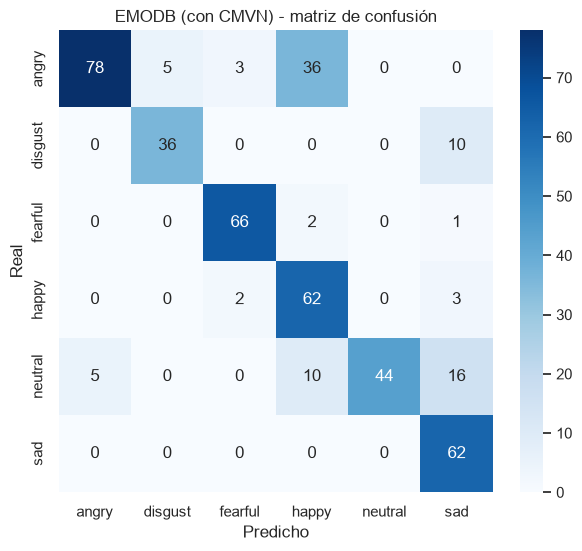

In [35]:
emodb_results = pd.DataFrame([
    {"variante": name, "accuracy": round(m["accuracy"], 3), "macro_f1": round(m["macro_f1"], 3)}
    for name, preds in [("sin CMVN", emodb_shared["pred_no_cmvn"]), ("con CMVN", emodb_shared["pred_cmvn"])]
    for m in [evaluate(emodb_shared["emotion"], preds, labels=SHARED_EMOTIONS)]
])
display(emodb_results)
plot_confusion_matrix(emodb_shared["emotion"], emodb_shared["pred_cmvn"], labels=SHARED_EMOTIONS,
                     title="EMODB (con CMVN) - matriz de confusión")
plt.show()